# T3 - Análise de dados do SIASUS para apoio à gestão municipal de saúde (Ijuí/RS)
**Fonte:** SIASUS/DATASUS, arquivo de produção ambulatorial `PARS2607` (RS, competência de movimentação 07/2026), carregado no MySQL (schema `sia`) e restrito ao município de Ijuí (`pa_ufmun = '431020'`) pela VIEW `sia.pa_ijui`.

## 1. Conexão e carga

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from conexao import usar_conexao

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
os.makedirs("figuras", exist_ok=True)

AZUL, LARANJA, CINZA = "#2a6f97", "#e07a1f", "#8a8f98"   # apresentado/aprovado e neutro
sns.set_theme(style="whitegrid", font_scale=0.95)

def consultar(sql):
    """Executa um SELECT no MySQL e devolve um DataFrame."""
    def acao(connection):
        with connection.cursor() as cursor:
            cursor.execute(sql)
            return pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)
    return usar_conexao(acao)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(f"figuras/{nome}.png", dpi=130, bbox_inches="tight")
    plt.show()

In [2]:
bruto = consultar("SELECT * FROM sia.pa_ijui")
grupos = consultar("SELECT co_grupo, no_grupo AS grupo FROM sia.tb_grupo")
grupos["grupo"] = grupos["grupo"].str.strip()   # o grupo 09 vem com \r\n no DBF
subgrupos = consultar("SELECT co_sub_gru, no_sub_gru AS subgrupo FROM sia.tb_subgr")
subgrupos["subgrupo"] = subgrupos["subgrupo"].str.strip()
tempo = consultar("SELECT Id, anomes, MAExt, anobi, anotri FROM sia.DIMTEMPO ORDER BY Id")

for c in ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]:
    bruto[c] = pd.to_numeric(bruto[c])
bruto.head()

Conexão estabelecida: <mysql.connector.connection.MySQLConnection object at 0x7fae9c564830>
Conexão estabelecida: <mysql.connector.connection.MySQLConnection object at 0x7fae73878050>
Conexão estabelecida: <mysql.connector.connection.MySQLConnection object at 0x7fae73878050>
Conexão estabelecida: <mysql.connector.connection.MySQLConnection object at 0x7fae73878690>


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr,pa_coduni,pa_proc_id,pa_cbocod,pa_munpcn,pa_tpups,pa_cmp,pa_mvm,AnoMes
0,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,041,0000,CID NAO INFORMADO,Ijui,Invalido,1,1,6.30,6.30,5610117,0301010048,251605,999999,70,202607,202607,202607
1,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,065,0000,CID NAO INFORMADO,Ijui,Invalido,3,3,18.90,18.90,5610117,0301010048,251510,999999,70,202607,202607,202607
2,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,059,0000,CID NAO INFORMADO,Ijui,Invalido,3,3,18.90,18.90,5610117,0301010048,251510,999999,70,202607,202607,202607
3,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,0,068,0000,CID NAO INFORMADO,Ijui,Invalido,3,3,18.90,18.90,5610117,0301010048,251510,999999,70,202607,202607,202607
4,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,0,035,0000,CID NAO INFORMADO,Ijui,Invalido,3,3,18.90,18.90,5610117,0301010048,251605,999999,70,202607,202607,202607


## 2. Análise exploratória

In [3]:
print("Linhas e colunas:", bruto.shape)
print()
bruto.info()

Linhas e colunas: (68827, 25)

<class 'pandas.DataFrame'>
RangeIndex: 68827 entries, 0 to 68826
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Ano                       68827 non-null  int64  
 1   Mes                       68827 non-null  int64  
 2   AnoBimestre               68827 non-null  str    
 3   AnoTrimestre              68827 non-null  str    
 4   Estabelecimento           68827 non-null  str    
 5   Procedimento              68827 non-null  str    
 6   Ocupacao                  68827 non-null  str    
 7   pa_sexo                   68827 non-null  str    
 8   pa_idade                  68827 non-null  str    
 9   pa_cidpri                 68827 non-null  str    
 10  Diagnostico               68818 non-null  str    
 11  MunicipioEstabelecimento  68827 non-null  str    
 12  MunicipioPaciente         68827 non-null  str    
 13  pa_qtdpro                 68827 non-null 

Tipos: as quantidades e os valores são **numéricos**; sexo, idade e CID são **códigos** (`pa_idade` vem como texto de 3 dígitos); estabelecimento, procedimento, ocupação, diagnóstico e municípios são **textuais/categóricos**.

In [4]:
num = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]
desc = bruto[num].describe().T
desc["mediana"] = bruto[num].median()
display(desc)

for col in ["pa_sexo", "pa_tpups", "pa_cmp", "Estabelecimento"]:
    print(f"\nDistribuição de frequências: {col}")
    display(bruto[col].value_counts(dropna=False).head(10).to_frame("registros"))

,count,mean,std,min,25%,50%,75%,max,mediana
pa_qtdpro,"68,827.00",6.70,54.82,0.00,1.00,1.00,1.00,"6,284.00",1.00
pa_qtdapr,"68,827.00",5.30,49.75,0.00,0.00,1.00,1.00,"5,337.00",1.00
pa_valpro,"68,827.00",91.13,580.94,0.00,3.37,6.30,17.67,"60,741.37",6.30
pa_valapr,"68,827.00",89.47,582.18,0.00,0.00,3.37,12.00,"60,741.37",3.37



Distribuição de frequências: pa_sexo


,registros
pa_sexo,
F,33636
M,32401
0,2790



Distribuição de frequências: pa_tpups


,registros
pa_tpups,
05,43399
36,8480
70,8199
68,6051
39,2378
73,235
42,85



Distribuição de frequências: pa_cmp


,registros
pa_cmp,
202607,68665
202606,152
202605,10



Distribuição de frequências: Estabelecimento


,registros
Estabelecimento,
HOSPITAL DE CLINICAS IJUI,24241
HOSPITAL BOM PASTOR IJUI,19158
17 COORDENADORIA REGIONAL DE SAUDE,6051
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,4326
APAE IJUI,3183
CER III UNIR,2838
CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO,2825
CENTRO AUDITIVO PROAUDI,2354
CISA,1766


### Valores ausentes e inválidos

In [5]:
ausentes = bruto.isna().sum().sort_values(ascending=False)
display(ausentes[ausentes > 0].to_frame("nulos (NaN)"))

idade_num = pd.to_numeric(bruto["pa_idade"], errors="coerce")
cid_nao_cadastrado = bruto["Diagnostico"].isna() & ~bruto["pa_cidpri"].isin(["0000", ""])
invalidos = pd.Series({
    "Sexo diferente de M/F": (~bruto["pa_sexo"].isin(["M", "F"])).sum(),
    "Idade fora de 0-120 (ex.: 999)": (~idade_num.between(0, 120)).sum(),
    "CID informado e inexistente na tabela CID": cid_nao_cadastrado.sum(),
    "CID principal = 0000 (não informado)": (bruto["pa_cidpri"] == "0000").sum(),
    "Município do paciente sem descrição": bruto["MunicipioPaciente"].isna().sum(),
    "Quantidade aprovada > apresentada": (bruto["pa_qtdapr"] > bruto["pa_qtdpro"]).sum(),
    "Linhas totalmente duplicadas": bruto.duplicated().sum(),
}).to_frame("registros")
invalidos["%"] = invalidos["registros"] / len(bruto) * 100
display(invalidos)
print("Valores distintos de sexo:", bruto["pa_sexo"].unique())
print("CIDs inexistentes:", bruto.loc[cid_nao_cadastrado, "pa_cidpri"].unique())

,nulos (NaN)
Diagnostico,9


,registros,%
Sexo diferente de M/F,2790,4.05
Idade fora de 0-120 (ex.: 999),955,1.39
CID informado e inexistente na tabela CID,9,0.01
CID principal = 0000 (não informado),46804,68.00
Município do paciente sem descrição,0,0.00
Quantidade aprovada > apresentada,0,0.00
Linhas totalmente duplicadas,27684,40.22


Valores distintos de sexo: <StringArray>
['0', 'F', 'M']
Length: 3, dtype: str
CIDs inexistentes: <StringArray>
['N183', 'N184']
Length: 2, dtype: str


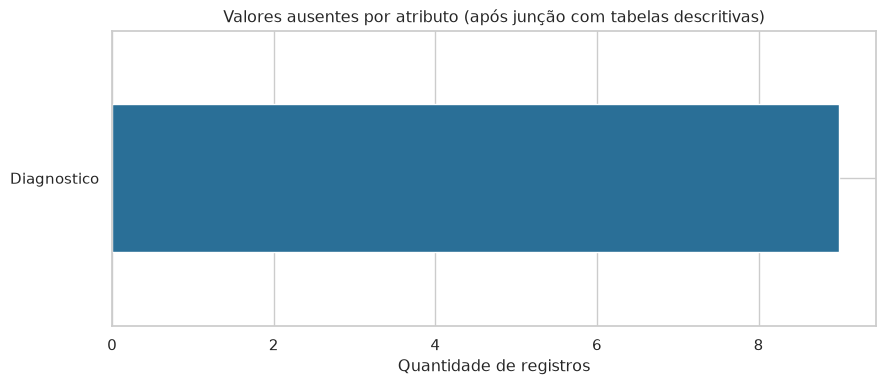

In [6]:
dados = ausentes[ausentes > 0].sort_values()
if len(dados):
    dados.plot(kind="barh", figsize=(9, 4), color=AZUL)
    plt.title("Valores ausentes por atributo (após junção com tabelas descritivas)")
    plt.xlabel("Quantidade de registros")
    salvar("01_ausentes")

**Interpretação:** a base tem 68.827 registros de Ijuí. Os problemas mais relevantes são: **CID não informado em 68%** dos registros (esperado: só alguns procedimentos exigem CID), **sexo `0` em 4,1%** e **idade 999 em 1,4%** (registros consolidados BPA-C, sem identificação do paciente, que também aparecem com município `999999`), e **9 registros com CID inexistente** na tabela (N18.3/N18.4, códigos de 4 caracteres ausentes da tabela). Não há quantidade aprovada maior que a apresentada. **40% das linhas são duplicatas exatas**, o que exige cautela (ver nota na limpeza). Como só o campo `Diagnostico` tem nulo após a junção, os demais descritivos estão completos.

## 3. Limpeza e preparação
Decisões (nenhuma linha é descartada por nulo, para não distorcer a produção):
- **Sexo** diferente de M/F → `Não informado` (código `0` ocorre em registros consolidados, BPA-C).
- **Idade** 999 ou fora de 0-120 → `NaN` (e faixa `Não informado`).
- **CID** `0000` → `Não informado`; CID informado sem descrição → `CID não cadastrado`.
- Descrições nulas (estabelecimento, procedimento, ocupação, município) → `Não informado`.
- **Duplicações:** registros idênticos em todas as colunas são removidos (`drop_duplicates`).

In [ ]:
df = bruto.copy()
df["Sexo"] = df["pa_sexo"].map({"M": "Masculino", "F": "Feminino"}).fillna("Não informado")
df["Idade"] = pd.to_numeric(df["pa_idade"], errors="coerce").where(lambda s: s.between(0, 120))
df["FaixaEtaria"] = pd.cut(df["Idade"], bins=[-1, 4, 11, 17, 29, 39, 49, 59, 69, 79, 120],
        labels=["0-4", "5-11", "12-17", "18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
        ).astype(object).fillna("Não informado")
df["CID"] = np.where(df["pa_cidpri"].isin(["0000", ""]), "Não informado", df["pa_cidpri"])
df["Diagnostico"] = np.where(df["CID"] == "Não informado", "Não informado",
                             df["Diagnostico"].fillna("CID não cadastrado"))
for col in ["Estabelecimento", "Procedimento", "Ocupacao", "MunicipioPaciente", "MunicipioEstabelecimento"]:
    df[col] = df[col].fillna("Não informado")
df["Grupo"] = df["pa_proc_id"].str[:2].map(grupos.set_index("co_grupo")["grupo"]).fillna("Não informado")
df["Subgrupo"] = df["pa_proc_id"].str[:4].map(subgrupos.set_index("co_sub_gru")["subgrupo"]).fillna("Não informado")

REMOVER_DUPLICADOS = True  
antes = df[num].sum()
if REMOVER_DUPLICADOS:
    df = df.drop_duplicates().reset_index(drop=True)
depois = df[num].sum()
print(f"Linhas: {len(bruto):,} -> {len(df):,} ({len(bruto)-len(df):,} duplicadas removidas)")
display(pd.DataFrame({"antes": antes, "depois": depois, "variação %": (depois/antes-1)*100}))

Linhas: 68,827 -> 41,143 (27,684 duplicadas removidas)


,antes,depois,variação %
pa_qtdpro,"461,059.00","416,977.00",-9.56
pa_qtdapr,"364,679.00","340,375.00",-6.66
pa_valpro,"6,272,060.94","5,808,842.24",-7.39
pa_valapr,"6,158,024.69","5,721,256.46",-7.09


> **Atenção:** no SIA, linhas idênticas podem ser atendimentos distintos (por exemplo, vários pacientes do mesmo perfil num BPA). A remoção segue o enunciado, mas a tabela acima mostra o impacto nos totais, que deve ser considerado na leitura.

## 4. Análises estratégicas para o gestor

### 4.1 Volume e perfil dos procedimentos

In [8]:
# Período mais recente (competência de atendimento) e janelas móveis de 1, 2 e 3 meses
meses = tempo[tempo["anomes"] <= df["AnoMes"].max()]["anomes"].tolist()
ultimo = meses[-1]
janelas = {"Último mês": meses[-1:], "Último bimestre": meses[-2:], "Último trimestre": meses[-3:]}
linhas = []
for nome, ms in janelas.items():
    f = df[df["AnoMes"].isin(ms)]
    linhas.append({"Período": nome, "Competências": f"{ms[0]} a {ms[-1]}", "Registros": len(f),
                   "Qtd. apresentada": f["pa_qtdpro"].sum(), "Qtd. aprovada": f["pa_qtdapr"].sum()})
volume_periodo = pd.DataFrame(linhas)
display(volume_periodo)

# Mesma contagem pelos agrupamentos de calendário da dimensão tempo (DIMTEMPO)
display(df.groupby("AnoBimestre")["pa_qtdapr"].sum().to_frame("Qtd. aprovada (bimestre)"))
display(df.groupby("AnoTrimestre")["pa_qtdapr"].sum().to_frame("Qtd. aprovada (trimestre)"))

,Período,Competências,Registros,Qtd. apresentada,Qtd. aprovada
0,Último mês,202607 a 202607,40987,416420,339936
1,Último bimestre,202606 a 202607,41134,416962,340373
2,Último trimestre,202605 a 202607,41143,416977,340375


,Qtd. aprovada (bimestre)
AnoBimestre,
2026B3,439
2026B4,339936


,Qtd. aprovada (trimestre)
AnoTrimestre,
2026T2,439
2026T3,339936


In [9]:
por_grupo = (df.groupby("Grupo").agg(Registros=("pa_qtdapr", "size"), QtdAprovada=("pa_qtdapr", "sum"),
             ValorAprovado=("pa_valapr", "sum")).sort_values("QtdAprovada", ascending=False))
por_grupo["% da qtd"] = por_grupo["QtdAprovada"] / por_grupo["QtdAprovada"].sum() * 100
display(por_grupo)

por_subgrupo = (df.groupby("Subgrupo").agg(QtdAprovada=("pa_qtdapr", "sum"), ValorAprovado=("pa_valapr", "sum"))
                .sort_values("QtdAprovada", ascending=False))
display(por_subgrupo.head(15))

top_proc = (df.groupby("Procedimento").agg(QtdAprovada=("pa_qtdapr", "sum"), ValorAprovado=("pa_valapr", "sum"))
            .sort_values("QtdAprovada", ascending=False).head(15))
display(top_proc)

,Registros,QtdAprovada,ValorAprovado,% da qtd
Grupo,,,,
Medicamentos,5713,201317,"902,528.84",59.15
Procedimentos com finalidade diagnostica,12753,82115,"1,078,218.92",24.12
Procedimentos clinicos,21292,54451,"2,677,962.87",16.00
Procedimentos cirurgicos,701,1194,"263,730.71",0.35
"Orteses, proteses e materiais especiais",569,849,"783,629.04",0.25
Acoes de promocao e prevencao em saude,20,354,780.88,0.10
"Transplantes de orgaos, tecidos e celulas",82,82,"11,165.20",0.02
Procedimentos para Ofertas de Cuidados Integrados,13,13,"3,240.00",0.00


,QtdAprovada,ValorAprovado
Subgrupo,,
Componente Especializado da Assitencia Farmaceutica,201317,"902,528.84"
Diagnostico em laboratorio clinico,68170,"332,828.25"
Consultas / Atendimentos / Acompanhamentos,49294,"238,523.77"
Metodos diagnosticos em especialidades,5551,"284,318.88"
Diagnostico por radiologia,2393,"28,379.49"
Tratamento em oncologia,1999,"1,970,604.87"
Tratamento em nefrologia,1710,"449,138.35"
Diagnostico por ultrasonografia,1675,"53,882.71"
Diagnostico por teste rapido,1463,6.00


,QtdAprovada,ValorAprovado
Procedimento,,
GABAPENTINA 300 MG (POR CAPSULA),13980,0.00
FORMOTEROL 12 MCG + BUDESONIDA 400 MCG Ç¨(POR CAPSULA INALANTE),13946,0.00
AZATIOPRINA 50 MG (POR COMPRIMIDO),10900,0.00
CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,8826,"88,080.00"
CLOZAPINA 100 MG (POR COMPRIMIDO),8333,0.00
TACROLIMO 1 MG (POR CAPSULA),7470,0.00
MESALAZINA 800 MG - POR COMPRIMIDOÇ¨,7120,0.00
SULFASSALAZINA 500 MG (POR COMPRIMIDO),6900,0.00
ATORVASTATINA 40 MG (POR COMPRIMIDO),6666,0.00


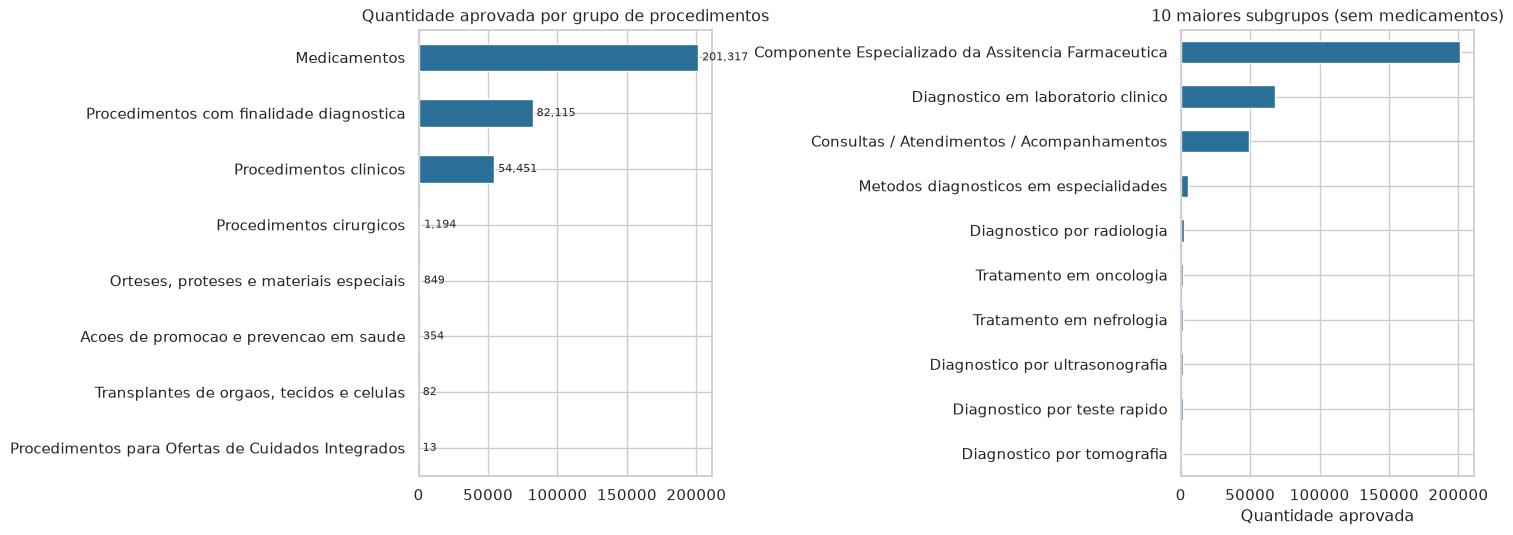

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
g = por_grupo["QtdAprovada"].sort_values()
g.plot(kind="barh", ax=axes[0], color=AZUL)
for i, v in enumerate(g): axes[0].text(v, i, f" {v:,.0f}", va="center", fontsize=8)
axes[0].set_title("Quantidade aprovada por grupo de procedimentos"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
sg = por_subgrupo.drop(index=[s for s in por_subgrupo.index if "edicamento" in s], errors="ignore")["QtdAprovada"].head(10).sort_values()
sg.plot(kind="barh", ax=axes[1], color=AZUL)
axes[1].set_title("10 maiores subgrupos (sem medicamentos)"); axes[1].set_xlabel("Quantidade aprovada"); axes[1].set_ylabel("")
salvar("02_volume_por_grupo")

**Interpretação:** no arquivo PARS 07/2026, Ijuí tem **340.375 procedimentos aprovados** (após limpeza). Como o arquivo traz uma única competência de movimentação (202607), as janelas de último mês, bimestre e trimestre quase coincidem (339.936 / 340.373 / 340.375); as competências retroativas (05 e 06) somam menos de 0,2%. **Medicamentos respondem por 59%** da quantidade (dispensação do Componente Especializado pela 17ª CRS, com valor unitário baixo ou zero); **diagnóstico (24%)** e **procedimentos clínicos (16%)** vêm a seguir. Excluindo medicamentos, dominam os exames laboratoriais (68 mil), as consultas/atendimentos (49 mil), a oncologia (~2 mil, de maior valor), a nefrologia e os exames de imagem. Cirurgias e transplantes são raros no ambulatorial.

,AnoMes,Registros,QtdApresentada,QtdAprovada,ValorAprovado,Var. % qtd aprovada
0,202605,9,15,2,320.00,NaN
1,202606,147,542,437,"36,924.16","21,750.00"
2,202607,40987,416420,339936,"5,684,012.30","77,688.56"


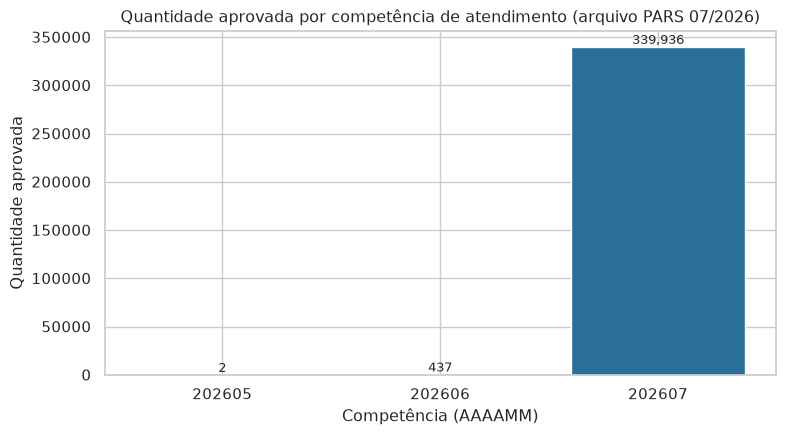

In [11]:
evolucao = (df.groupby("AnoMes").agg(Registros=("pa_qtdapr", "size"), QtdApresentada=("pa_qtdpro", "sum"),
            QtdAprovada=("pa_qtdapr", "sum"), ValorAprovado=("pa_valapr", "sum")).reset_index())
evolucao["Var. % qtd aprovada"] = evolucao["QtdAprovada"].pct_change() * 100
display(evolucao)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(evolucao["AnoMes"], evolucao["QtdAprovada"], color=AZUL)
for x, v in zip(evolucao["AnoMes"], evolucao["QtdAprovada"]): ax.text(x, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Quantidade aprovada por competência de atendimento (arquivo PARS 07/2026)")
ax.set_xlabel("Competência (AAAAMM)"); ax.set_ylabel("Quantidade aprovada")
salvar("03_evolucao_competencia")

**Interpretação:** só há uma competência completa (07/2026); 05 e 06 são apresentações retroativas (437 aprovados em 06 e 2 em 05), então o aumento de "77 mil %" **não é tendência** e sim efeito do arquivo. Não é possível apontar picos ou quedas de demanda com este arquivo; para isso é preciso carregar vários meses de PARS (o modelo já suporta, bastando carregar os demais arquivos e a DIMTEMPO).

### 4.2 Produção por estabelecimento de saúde

In [12]:
estab = (df.groupby("Estabelecimento").agg(Registros=("pa_qtdapr", "size"), QtdApresentada=("pa_qtdpro", "sum"),
         QtdAprovada=("pa_qtdapr", "sum"), ValorApresentado=("pa_valpro", "sum"), ValorAprovado=("pa_valapr", "sum"))
         .sort_values("QtdAprovada", ascending=False))
estab["% aprovada/apresentada"] = estab["QtdAprovada"] / estab["QtdApresentada"] * 100
estab["Diferença qtd"] = estab["QtdApresentada"] - estab["QtdAprovada"]
estab["Diferença R$"] = estab["ValorApresentado"] - estab["ValorAprovado"]
display(estab.head(15))
print("Total de estabelecimentos com produção:", len(estab))
# Excluindo medicamentos (dispensação da Coordenadoria Regional de Saúde distorce o ranking por quantidade)
sem_med = (df[~df["Grupo"].str.contains("edicamento")].groupby("Estabelecimento")["pa_qtdapr"].sum()
           .sort_values(ascending=False).to_frame("Qtd. aprovada (sem medicamentos)"))
display(sem_med.head(10))

,Registros,QtdApresentada,QtdAprovada,ValorApresentado,ValorAprovado,% aprovada/apresentada,Diferença qtd,Diferença R$
Estabelecimento,,,,,,,,
17 COORDENADORIA REGIONAL DE SAUDE,5713,258951,201317,"908,410.84","902,528.84",77.74,57634,"5,882.00"
HOSPITAL DE CLINICAS IJUI,17946,39488,34238,"3,394,649.59","3,300,149.65",86.70,5250,"94,499.94"
LABORATORIO DE ANALISES CLINICAS UNILAB,234,29654,29654,"146,797.58","146,797.58",100.00,0,0.00
CISA,1724,30511,24634,"215,168.47","166,120.66",80.74,5877,"49,047.81"
UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR AGNOLETTO,194,24874,21525,"68,317.20","65,916.54",86.54,3349,"2,400.66"
HEMOVITA,138,8096,8096,"41,978.33","41,978.33",100.00,0,0.00
HOSPITAL BOM PASTOR IJUI,7018,7022,4174,"196,398.48","264,900.29",59.44,2848,"-68,501.81"
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,1956,4128,3103,"4,624.20","4,624.20",75.17,1025,0.00
CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,721,3167,3020,"9,161.82","9,161.82",95.36,147,0.00


Total de estabelecimentos com produção: 18


,Qtd. aprovada (sem medicamentos)
Estabelecimento,
HOSPITAL DE CLINICAS IJUI,34238
LABORATORIO DE ANALISES CLINICAS UNILAB,29654
CISA,24634
UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR AGNOLETTO,21525
HEMOVITA,8096
HOSPITAL BOM PASTOR IJUI,4174
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,3103
CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,3020
CENTRO AUDITIVO PROAUDI,2820


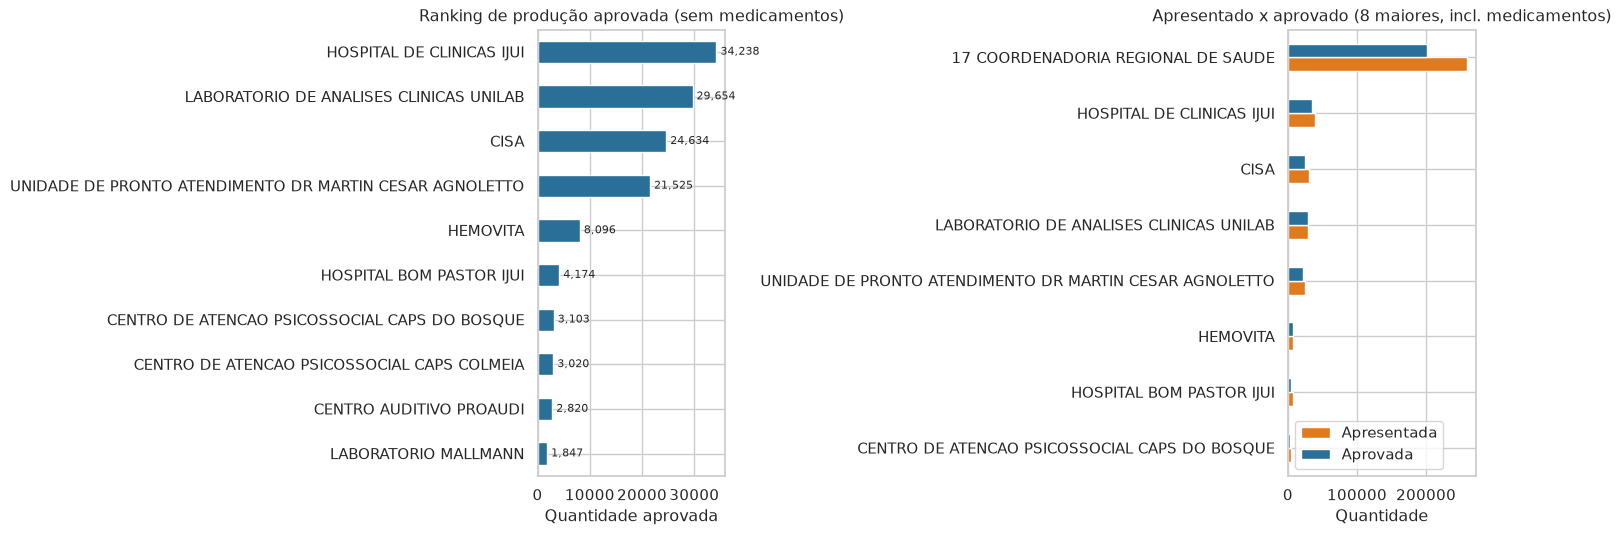

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
t = sem_med["Qtd. aprovada (sem medicamentos)"].head(10).sort_values()
t.plot(kind="barh", ax=axes[0], color=AZUL)
for i, v in enumerate(t): axes[0].text(v, i, f" {v:,.0f}", va="center", fontsize=8)
axes[0].set_title("Ranking de produção aprovada (sem medicamentos)"); axes[0].set_ylabel(""); axes[0].set_xlabel("Quantidade aprovada")
cmp = estab.nlargest(8, "QtdApresentada")[["QtdApresentada", "QtdAprovada"]].iloc[::-1]
cmp.plot(kind="barh", ax=axes[1], color=[LARANJA, AZUL])
axes[1].set_title("Apresentado x aprovado (8 maiores, incl. medicamentos)"); axes[1].set_ylabel(""); axes[1].set_xlabel("Quantidade")
axes[1].legend(["Apresentada", "Aprovada"])
salvar("04_ranking_estabelecimentos")

**Interpretação:** em quantidade, a **17ª Coordenadoria Regional de Saúde** lidera por causa dos medicamentos (201 mil aprovados, 77,7% do apresentado). Sem medicamentos, o ranking é: **Hospital de Clínicas de Ijuí (34,2 mil)**, Unilab (29,7 mil), CISA (24,6 mil), UPA Dr. Martin Cesar Agnoletto (21,5 mil), Hemovita (8,1 mil) e **Hospital Bom Pastor (4,2 mil)**. Os laboratórios, Hemovita e Proaudi tiveram 100% de aprovação. Atenção: **Bom Pastor aprovou apenas 59% da quantidade apresentada**, mas o valor aprovado (R$ 264,9 mil) superou o apresentado (R$ 196,4 mil), indicando valores acrescidos na aprovação (incrementos/FAEC); CISA (81%) e HCI (87%) também têm diferenças a verificar. Não aparecem UBS: a atenção básica é registrada no e-SUS APS, não no SIASUS.

### 4.3 Perfil demográfico e epidemiológico

In [14]:
atend = df[df["pa_qtdapr"] > 0]
sexo = df.groupby("Sexo")["pa_qtdapr"].sum().to_frame("Qtd. aprovada")
sexo["%"] = sexo["Qtd. aprovada"] / sexo["Qtd. aprovada"].sum() * 100
display(sexo)
ordem = ["0-4", "5-11", "12-17", "18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+", "Não informado"]
perfil = pd.crosstab(df["FaixaEtaria"], df["Sexo"], values=df["pa_qtdapr"], aggfunc="sum").reindex(ordem).fillna(0)
display(perfil)

cid = (df[df["CID"] != "Não informado"].groupby(["CID", "Diagnostico"])["pa_qtdapr"].agg(["size", "sum"])
       .rename(columns={"size": "Registros", "sum": "QtdAprovada"}).sort_values("Registros", ascending=False))
display(cid.head(15))

def categoria(cid):
    if cid == "Não informado": return "Sem CID"
    if "I10" <= cid[:3] <= "I15": return "Hipertensão (I10-I15)"
    if "E10" <= cid[:3] <= "E14": return "Diabetes (E10-E14)"
    if cid[0] == "C" or ("D00" <= cid[:3] <= "D48"): return "Câncer/neoplasias (C00-D48)"
    if cid[0] == "F": return "Transtornos mentais (F)"
    if "J40" <= cid[:3] <= "J47": return "Asma/DPOC (J40-J47)"
    if cid[0] == "N" and cid[:3] in ("N17", "N18", "N19"): return "Doença renal (N17-N19)"
    return "Outros"
df["CategoriaCID"] = df["CID"].map(categoria)
cat = (df[df["CategoriaCID"] != "Sem CID"].groupby("CategoriaCID").agg(Registros=("pa_qtdapr", "size"), QtdAprovada=("pa_qtdapr", "sum"))
       .sort_values("Registros", ascending=False))
display(cat)

,Qtd. aprovada,%
Sexo,,
Feminino,130110,38.23
Masculino,99251,29.16
Não informado,111014,32.62


Sexo,Feminino,Masculino,Não informado
FaixaEtaria,,,
0-4,268.00,594.00,632.00
5-11,"1,673.00","1,835.00","4,009.00"
12-17,"2,396.00","2,617.00",721.00
18-29,"8,926.00","6,942.00","1,013.00"
30-39,"9,989.00","12,106.00","1,458.00"
40-49,"18,096.00","11,988.00","1,313.00"
50-59,"25,382.00","16,784.00","1,177.00"
60-69,"29,863.00","22,127.00",901.00
70-79,"21,965.00","17,543.00",605.00


,,Registros,QtdAprovada
CID,Diagnostico,,
H905,H90.5 Perda de audicao neuro-sensorial NE,2030,2414
I516,I51.6 Doenc cardiovascular NE,1056,739
R520,R52.0 Dor aguda,774,475
J450,J45.0 Asma predom alergica,672,13266
C501,C50.1 Porcao central da mama,570,543
C61,C61 Neopl malig da prostata,466,441
R529,R52.9 Dor NE,437,253
I200,I20.0 Angina instavel,430,576
C500,C50.0 Mamilo e areola,396,388


,Registros,QtdAprovada
CategoriaCID,,
Outros,10464,149994
Câncer/neoplasias (C00-D48),2445,2413
Transtornos mentais (F),1624,31821
Asma/DPOC (J40-J47),1366,23250
Diabetes (E10-E14),526,2560
Doença renal (N17-N19),184,1436
Hipertensão (I10-I15),1,1


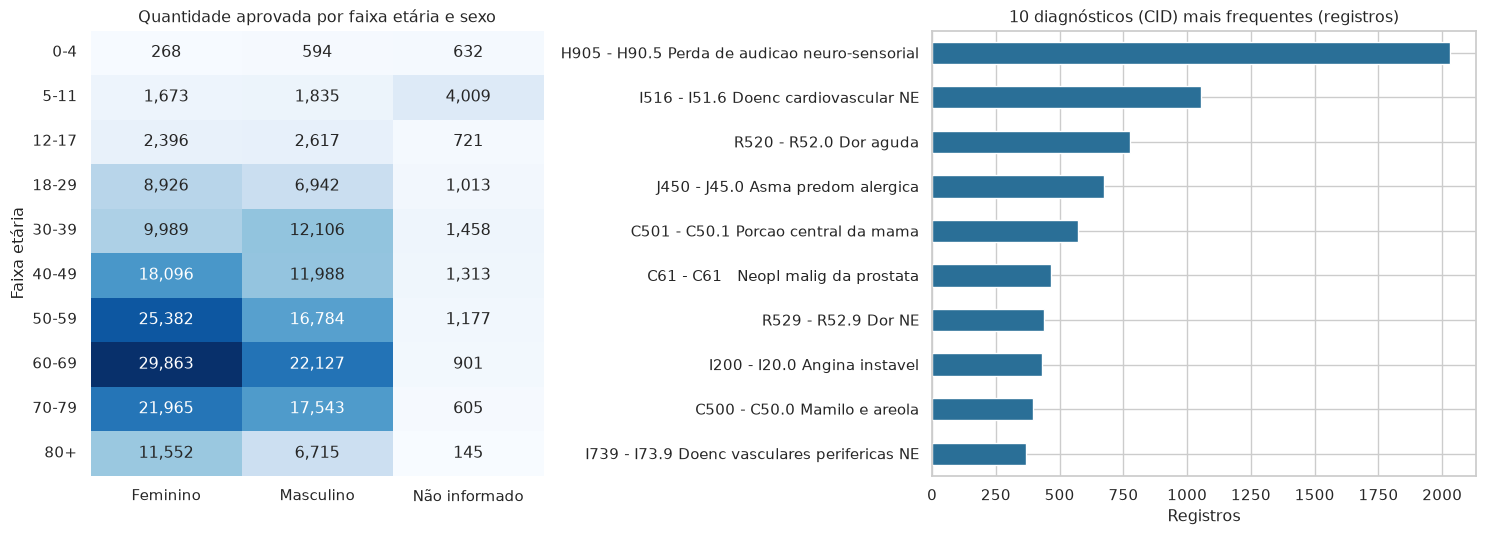

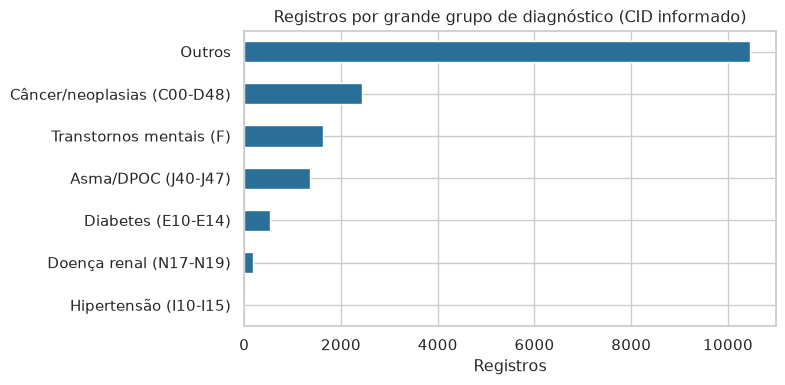

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(perfil.drop(index="Não informado"), annot=True, fmt=",.0f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Quantidade aprovada por faixa etária e sexo"); axes[0].set_xlabel(""); axes[0].set_ylabel("Faixa etária")
c = cid.head(10)["Registros"].copy()
c.index = [f"{a} - {b[:38]}" for a, b in c.index]
c.sort_values().plot(kind="barh", ax=axes[1], color=AZUL)
axes[1].set_title("10 diagnósticos (CID) mais frequentes (registros)"); axes[1].set_ylabel(""); axes[1].set_xlabel("Registros")
salvar("05_perfil_demografico_cid")

fig, ax = plt.subplots(figsize=(8, 4))
cat["Registros"].sort_values().plot(kind="barh", ax=ax, color=AZUL)
ax.set_title("Registros por grande grupo de diagnóstico (CID informado)"); ax.set_ylabel(""); ax.set_xlabel("Registros")
salvar("06_categorias_cid")

**Interpretação:** entre os registros com sexo informado, há mais **mulheres (130 mil)** do que homens (99 mil) em quantidade aprovada; 33% da quantidade não tem sexo informado (BPA consolidado). A demanda concentra-se em **50-79 anos**, sobretudo 60-69 (cerca de 53 mil), compatível com doenças crônicas e com a oncologia; há também uma presença relevante de crianças de 5-11 anos (CAPS infantil, APAE). Entre os CIDs, destacam-se **perda de audição (H90.5, Proaudi)**, doença cardiovascular, dor aguda, asma (J45.0), **câncer de mama (C50) e de próstata (C61)**, artrite reumatoide e **transtornos do desenvolvimento/autismo (F84)**. Por grande grupo, neoplasias somam 2.445 registros e transtornos mentais, 1.624.

### 4.4 Fluxos regionais e acesso

In [16]:
df["Residente"] = np.where(df["pa_munpcn"] == "431020", "Ijuí", "Outros municípios")
# 999999 = município inválido/ignorado (registros consolidados, sem identificação do paciente)
df.loc[df["pa_munpcn"].isin(["", "000000", "999999"]) | df["pa_munpcn"].isna(), "Residente"] = "Não informado"
res = df.groupby("Residente").agg(Registros=("pa_qtdapr", "size"), QtdAprovada=("pa_qtdapr", "sum"))
res["% registros"] = res["Registros"] / res["Registros"].sum() * 100
res["% qtd"] = res["QtdAprovada"] / res["QtdAprovada"].sum() * 100
display(res)

origem = (df[df["Residente"] != "Não informado"].groupby(["pa_munpcn", "MunicipioPaciente"]).agg(Registros=("pa_qtdapr", "size"), QtdAprovada=("pa_qtdapr", "sum"))
          .sort_values("Registros", ascending=False).reset_index())
display(origem.head(15))
fora = df[df["Residente"] == "Outros municípios"]
print("Atendimentos (registros) de moradores de outros municípios:", len(fora), f"({len(fora)/len(df)*100:.1f}%)")
print("Municípios de origem distintos:", fora["pa_munpcn"].nunique())
conhecidos = df[df["Residente"] != "Não informado"]
print(f"Entre os registros com município válido, {len(fora)/len(conhecidos)*100:.1f}% são de moradores de outros municípios")
print("De outras UFs (código IBGE não iniciado em 43):", (fora["pa_munpcn"].str[:2] != "43").sum(), "registros")

,Registros,QtdAprovada,% registros,% qtd
Residente,,,,
Ijuí,14232,84819,34.59,24.92
Não informado,2788,111014,6.78,32.62
Outros municípios,24123,144542,58.63,42.47


,pa_munpcn,MunicipioPaciente,Registros,QtdAprovada
0,431020,Ijui,14232,84819
1,431390,Panambi,2429,35295
2,431115,Joia,1677,9687
3,430600,Crissiumal,1257,13468
4,430500,Catuipe,1252,8863
5,430150,Augusto Pestana,1116,8144
6,431780,Santo Augusto,1043,8353
7,430570,Condor,904,9238
8,430020,Ajuricaba,841,7591
9,431750,Santo Angelo,794,671


Atendimentos (registros) de moradores de outros municípios: 24123 (58.6%)
Municípios de origem distintos: 183
Entre os registros com município válido, 62.9% são de moradores de outros municípios
De outras UFs (código IBGE não iniciado em 43): 54 registros


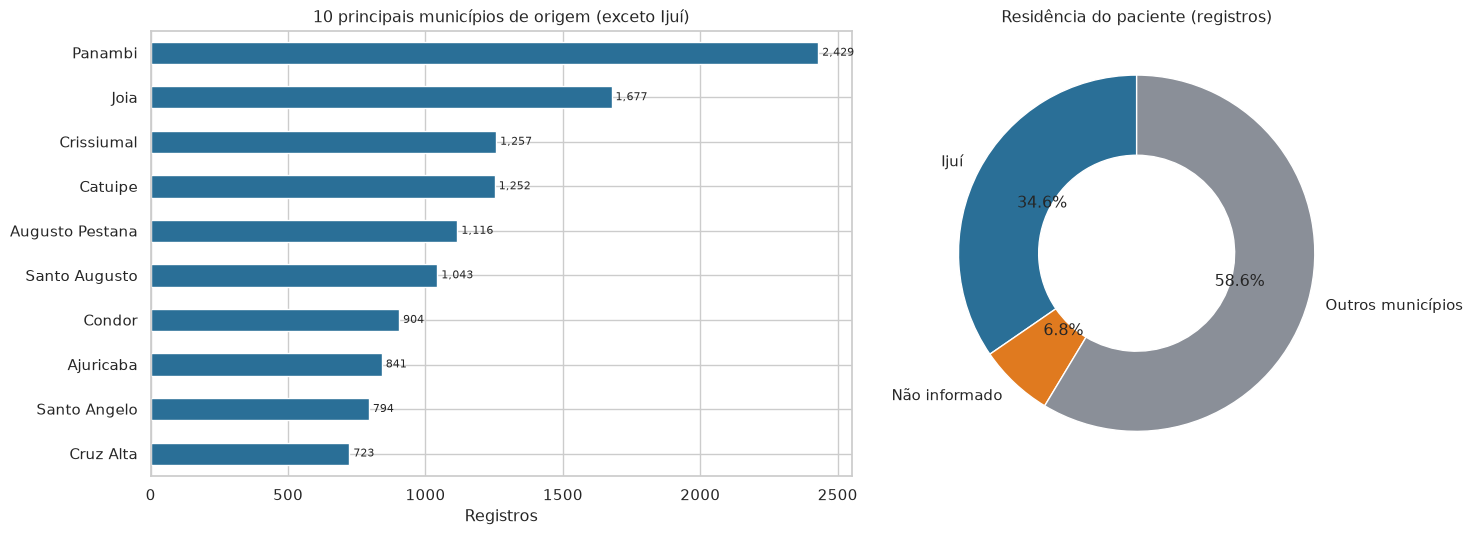

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
o = origem[origem["pa_munpcn"] != "431020"].head(10).set_index("MunicipioPaciente")["Registros"].sort_values()
o.plot(kind="barh", ax=axes[0], color=AZUL)
for i, v in enumerate(o): axes[0].text(v, i, f" {v:,.0f}", va="center", fontsize=8)
axes[0].set_title("10 principais municípios de origem (exceto Ijuí)"); axes[0].set_ylabel(""); axes[0].set_xlabel("Registros")
r = res["Registros"]
axes[1].pie(r, labels=r.index, autopct="%1.1f%%", startangle=90, colors=[AZUL, LARANJA, CINZA][:len(r)], wedgeprops={"width": 0.45})
axes[1].set_title("Residência do paciente (registros)")
salvar("07_fluxos_regionais")

**Interpretação:** descartando os registros sem município válido (6,8%), **62,9% dos atendimentos em Ijuí são de moradores de outros municípios** (24.123 registros, de 183 municípios distintos; só 54 de outras UFs), o que confirma a vocação de **polo regional**. Os principais municípios de origem são **Panambi (2.429)**, Joia, Crissiumal, Catuípe, Augusto Pestana, Santo Augusto, Condor e Ajuricaba, todos do entorno. Isso importa para o planejamento: a demanda real supera a população do município, e pactuações/financiamento regional precisam refletir esse fluxo.

### 4.5 Recursos financeiros

In [18]:
fin = pd.DataFrame([{"Valor apresentado (produzido)": df["pa_valpro"].sum(), "Valor aprovado": df["pa_valapr"].sum()}])
fin["Diferença (produzido - aprovado)"] = fin.iloc[0, 0] - fin.iloc[0, 1]
fin["% aprovado"] = fin["Valor aprovado"] / fin["Valor apresentado (produzido)"] * 100
display(fin)

fin_grupo = df.groupby("Grupo").agg(ValorProduzido=("pa_valpro", "sum"), ValorAprovado=("pa_valapr", "sum"),
                                    QtdAprovada=("pa_qtdapr", "sum"))
fin_grupo["Diferença"] = fin_grupo["ValorProduzido"] - fin_grupo["ValorAprovado"]
display(fin_grupo.sort_values("ValorAprovado", ascending=False))

# Gasto médio por unidade de procedimento aprovado, por competência
gasto = df.groupby("AnoMes").agg(ValorAprovado=("pa_valapr", "sum"), QtdAprovada=("pa_qtdapr", "sum"))
gasto["Gasto médio (R$/proc.)"] = gasto["ValorAprovado"] / gasto["QtdAprovada"]
gasto["Variação %"] = gasto["Gasto médio (R$/proc.)"].pct_change() * 100
display(gasto)
sem_med_df = df[~df["Grupo"].str.contains("edicamento")]
gasto_sm = sem_med_df.groupby("AnoMes").apply(lambda g: g["pa_valapr"].sum() / g["pa_qtdapr"].sum(), include_groups=False)
print("Gasto médio por procedimento, sem medicamentos:"); display(gasto_sm.to_frame("R$/proc."))

,Valor apresentado (produzido),Valor aprovado,Diferença (produzido - aprovado),% aprovado
0,"5,808,842.24","5,721,256.46","87,585.78",98.49


,ValorProduzido,ValorAprovado,QtdAprovada,Diferença
Grupo,,,,
Procedimentos clinicos,"2,722,810.13","2,677,962.87",54451,"44,847.26"
Procedimentos com finalidade diagnostica,"1,207,433.14","1,078,218.92",82115,"129,214.22"
Medicamentos,"908,410.84","902,528.84",201317,"5,882.00"
"Orteses, proteses e materiais especiais","784,634.94","783,629.04",849,"1,005.90"
Procedimentos cirurgicos,"170,367.11","263,730.71",1194,"-93,363.60"
"Transplantes de orgaos, tecidos e celulas","11,165.20","11,165.20",82,0.00
Procedimentos para Ofertas de Cuidados Integrados,"3,240.00","3,240.00",13,0.00
Acoes de promocao e prevencao em saude,780.88,780.88,354,0.00


,ValorAprovado,QtdAprovada,Gasto médio (R$/proc.),Variação %
AnoMes,,,,
202605,320.00,2,160.00,NaN
202606,"36,924.16",437,84.49,-47.19
202607,"5,684,012.30",339936,16.72,-80.21


Gasto médio por procedimento, sem medicamentos:


,R$/proc.
AnoMes,
202605,160.00
202606,84.49
202607,34.49


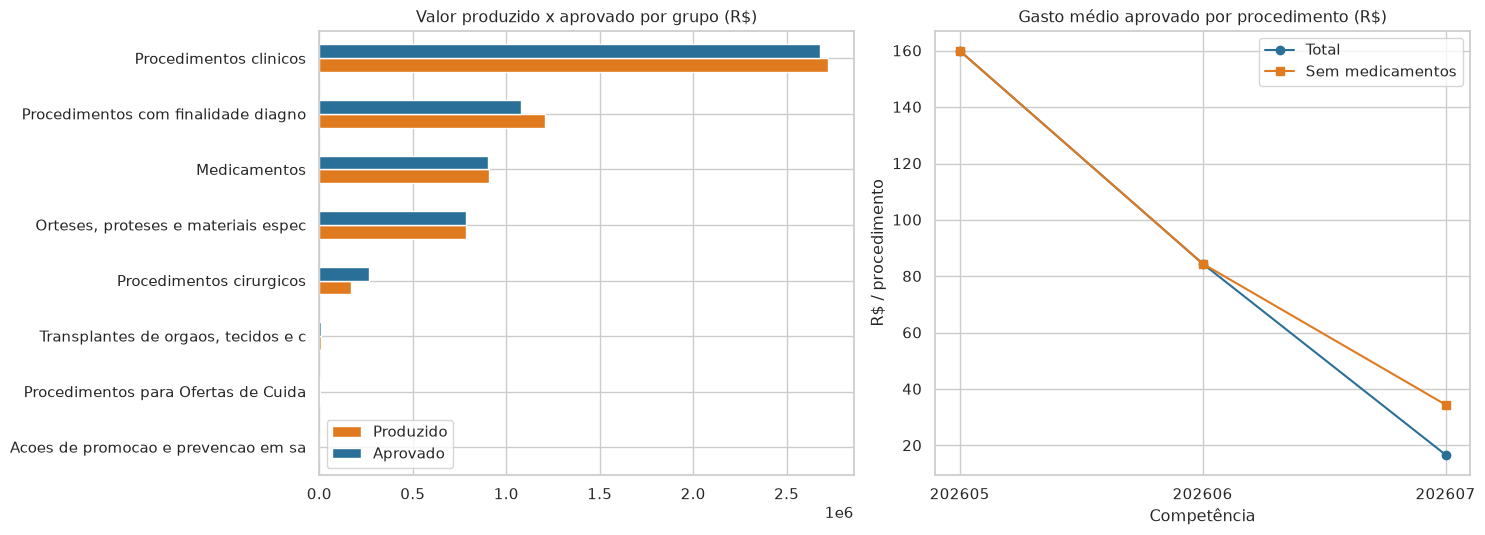

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
fg = fin_grupo.sort_values("ValorProduzido")[["ValorProduzido", "ValorAprovado"]]
fg.index = [i[:35] for i in fg.index]
fg.plot(kind="barh", ax=axes[0], color=[LARANJA, AZUL])
axes[0].set_title("Valor produzido x aprovado por grupo (R$)"); axes[0].set_ylabel(""); axes[0].legend(["Produzido", "Aprovado"])
gasto["Gasto médio (R$/proc.)"].plot(ax=axes[1], marker="o", color=AZUL, label="Total")
gasto_sm.plot(ax=axes[1], marker="s", color=LARANJA, label="Sem medicamentos")
axes[1].set_title("Gasto médio aprovado por procedimento (R$)"); axes[1].set_xlabel("Competência"); axes[1].set_ylabel("R$ / procedimento"); axes[1].legend()
axes[1].set_xticks(range(len(gasto))); axes[1].set_xticklabels(gasto.index)
salvar("08_financeiro")

**Interpretação:** foram **apresentados R$ 5,81 milhões** e **aprovados R$ 5,72 milhões** (98,5%), uma diferença de R$ 87,6 mil. A diferença se concentra em **diagnóstico (R$ 129 mil)** e **procedimentos clínicos (R$ 45 mil)**; em **cirurgias o aprovado supera o apresentado em R$ 93 mil**, o que sugere acréscimos de valor na aprovação e merece conferência. O **gasto médio por procedimento em 07/2026 foi R$ 16,72** (R$ 34,49 sem medicamentos). A série mensal é irrelevante, pois 05 e 06 têm volume mínimo (2 e 437 procedimentos). Medicamentos pesam muito em quantidade e pouco em valor (R$ 0,9 mi); os maiores valores vêm de clínicos (R$ 2,7 mi), diagnóstico (R$ 1,1 mi) e OPM (R$ 0,8 mi).

### 4.6 Foco em áreas críticas

#### Oncologia: quimioterapia e radioterapia (aprovados x produzidos)

In [20]:
onco = df[df["pa_proc_id"].str.startswith("0304")].copy()
def tipo_onco(d):
    d = d.upper()
    if "QUIMIOTERAPIA" in d: return "Quimioterapia"
    if "RADIOTERAPIA" in d: return "Radioterapia"
    if "HORMONIOTERAPIA" in d: return "Hormonioterapia"
    return "Outros (oncologia)"
onco["Tipo"] = onco["Procedimento"].map(tipo_onco)
onco_t = onco.groupby("Tipo").agg(Registros=("pa_qtdapr", "size"), QtdProduzida=("pa_qtdpro", "sum"), QtdAprovada=("pa_qtdapr", "sum"),
                                  ValorProduzido=("pa_valpro", "sum"), ValorAprovado=("pa_valapr", "sum"))
onco_t["Dif. qtd"] = onco_t["QtdProduzida"] - onco_t["QtdAprovada"]
onco_t["Dif. R$"] = onco_t["ValorProduzido"] - onco_t["ValorAprovado"]
display(onco_t)
print("Estabelecimentos:"); display(onco.groupby("Estabelecimento")[["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]].sum())

,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,Dif. qtd,Dif. R$
Tipo,,,,,,,
Hormonioterapia,1066,1012,1011,"144,050.42","143,970.67",1,79.75
Outros (oncologia),159,155,155,"98,768.40","98,768.40",0,0.00
Quimioterapia,686,600,600,"909,337.10","909,337.10",0,0.00
Radioterapia,210,234,233,"822,270.30","818,528.70",1,"3,741.60"


Estabelecimentos:


,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
Estabelecimento,,,,
HOSPITAL DE CLINICAS IJUI,2001,1999,"1,974,426.22","1,970,604.87"


#### Saúde mental: atendimentos psiquiátricos e psicológicos

In [21]:
sm = df.copy()
sm["CAPS"] = sm["pa_proc_id"].str.startswith("030108")
sm["Psicólogo (CBO 2515)"] = sm["pa_cbocod"].str.startswith("2515")
sm["Psiquiatra (CBO 225133)"] = sm["pa_cbocod"] == "225133"
sm["CID F (transtornos mentais)"] = sm["CID"].str.startswith("F")
flags = ["CAPS", "Psicólogo (CBO 2515)", "Psiquiatra (CBO 225133)", "CID F (transtornos mentais)"]
saude_mental = pd.DataFrame({f: {"Registros": sm.loc[sm[f]].shape[0], "QtdAprovada": sm.loc[sm[f], "pa_qtdapr"].sum(),
                                 "QtdProduzida": sm.loc[sm[f], "pa_qtdpro"].sum(), "ValorAprovado": sm.loc[sm[f], "pa_valapr"].sum()} for f in flags}).T
display(saude_mental)
any_sm = sm[sm[flags].any(axis=1)]
print("Registros com algum critério de saúde mental:", len(any_sm))
display(any_sm.groupby("Estabelecimento")["pa_qtdapr"].sum().sort_values(ascending=False).head(8).to_frame("Qtd. aprovada"))
display(any_sm[any_sm["CID"].str.startswith("F")].groupby(["CID", "Diagnostico"]).size().sort_values(ascending=False).head(8).to_frame("Registros"))

,Registros,QtdAprovada,QtdProduzida,ValorAprovado
CAPS,"2,928.00","3,365.00","4,822.00",0.00
Psicólogo (CBO 2515),"1,302.00","1,920.00","2,150.00","8,998.48"
Psiquiatra (CBO 225133),334.00,"1,143.00","1,157.00","9,810.00"
CID F (transtornos mentais),"1,624.00","31,821.00","32,005.00","12,869.67"


Registros com algum critério de saúde mental: 5227


,Qtd. aprovada
Estabelecimento,
17 COORDENADORIA REGIONAL DE SAUDE,30859
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,2024
CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,1501
CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO,1280
CER III UNIR,533
CISA,510
APAE IJUI,486
HOSPITAL DE CLINICAS IJUI,183


,,Registros
CID,Diagnostico,
F849,F84.9 Transt globais NE do desenvolv,304
F840,F84.0 Autismo infantil,237
F710,F71.0 Mencao ausencia de ou compr minimo comport,165
F200,F20.0 Esquizofrenia paranoide,132
F700,F70.0 Mencao ausencia de ou compr minimo comport,127
F848,F84.8 Outr transt globais do desenvolv,49
F315,F31.5 Trans afet bip atual depr grav c/sint psicot,45
F317,F31.7 Transt afet bipolar atualmente em remissao,44


#### Atenção básica: consultas e procedimentos, acompanhamento de doenças crônicas

In [22]:
print("Tipos de unidade (PA_TPUPS) presentes:"); display(df.groupby("pa_tpups")["pa_qtdapr"].agg(["size", "sum"]))
ab = df[df["pa_proc_id"].str.startswith("030101")]
print("Consultas e atendimentos (subgrupo 0301 01 - consultas médicas/outros profissionais de nível superior):")
display(ab.groupby("Procedimento")[["pa_qtdapr", "pa_valapr"]].sum().sort_values("pa_qtdapr", ascending=False).head(10))
display(ab.groupby("Estabelecimento")["pa_qtdapr"].sum().sort_values(ascending=False).head(8).to_frame("Qtd. aprovada"))
acoes = df[df["pa_proc_id"].str.startswith("0101")]
print("Ações coletivas/individuais de promoção e prevenção (grupo 0101):", acoes["pa_qtdapr"].sum())

cron = df[df["CategoriaCID"].isin(["Hipertensão (I10-I15)", "Diabetes (E10-E14)", "Asma/DPOC (J40-J47)", "Doença renal (N17-N19)"])]
display(cron.groupby("CategoriaCID").agg(Registros=("pa_qtdapr", "size"), QtdAprovada=("pa_qtdapr", "sum"),
                                         Estabelecimentos=("Estabelecimento", "nunique")))
display(cron.groupby(["CategoriaCID", "Estabelecimento"])["pa_qtdapr"].sum().sort_values(ascending=False).head(10).to_frame("Qtd. aprovada"))

Tipos de unidade (PA_TPUPS) presentes:


,size,sum
pa_tpups,,
05,24964,38412
36,4290,5185
39,2249,65551
42,84,587
68,5713,201317
70,3649,7798
73,194,21525


Consultas e atendimentos (subgrupo 0301 01 - consultas médicas/outros profissionais de nível superior):


,pa_qtdapr,pa_valapr
Procedimento,,
CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,8826,"88,080.00"
CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA ATENCAO ESPECIALIZADA (EXCETO MEDICO),4636,"29,206.80"
CONSULTA MEDICA EM ATENCAO PRIMARIA,2705,0.00
PRIMEIRA CONSULTA ODONTOLOGICA PROGRAMATICA,2076,0.00
CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA ATENCAO PRIMARIA (EXCETO MEDICO),609,0.00
CONSULTA MEDICA EM SAUDE DO TRABALHADOR,29,290.00
CONSULTA/ATENDIMENTO DOMICILIAR NA ATENCAO ESPECIALIZADA,21,65.94
CONSULTA/ATENDIMENTO DOMICILIAR,4,0.00


,Qtd. aprovada
Estabelecimento,
CISA,8363
HOSPITAL DE CLINICAS IJUI,5603
CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,1507
HOSPITAL BOM PASTOR IJUI,1135
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,1044
CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO,740
CER III UNIR,174
CENTRO AUDITIVO PROAUDI,130


Ações coletivas/individuais de promoção e prevenção (grupo 0101): 341


,Registros,QtdAprovada,Estabelecimentos
CategoriaCID,,,
Asma/DPOC (J40-J47),1366,23250,2
Diabetes (E10-E14),526,2560,2
Doença renal (N17-N19),184,1436,3
Hipertensão (I10-I15),1,1,1


Qtd. aprovada
CategoriaCID           Estabelecimento                                  
Asma/DPOC (J40-J47)    17 COORDENADORIA REGIONAL DE SAUDE          23246
Diabetes (E10-E14)     17 COORDENADORIA REGIONAL DE SAUDE           2553
Doença renal (N17-N19) 17 COORDENADORIA REGIONAL DE SAUDE           1426
                       HOSPITAL BOM PASTOR IJUI                        8
Diabetes (E10-E14)     CER III UNIR                                    7
Asma/DPOC (J40-J47)    HOSPITAL BOM PASTOR IJUI                        4
Doença renal (N17-N19) HOSPITAL DE CLINICAS IJUI                       2
Hipertensão (I10-I15)  HOSPITAL BOM PASTOR IJUI                        1

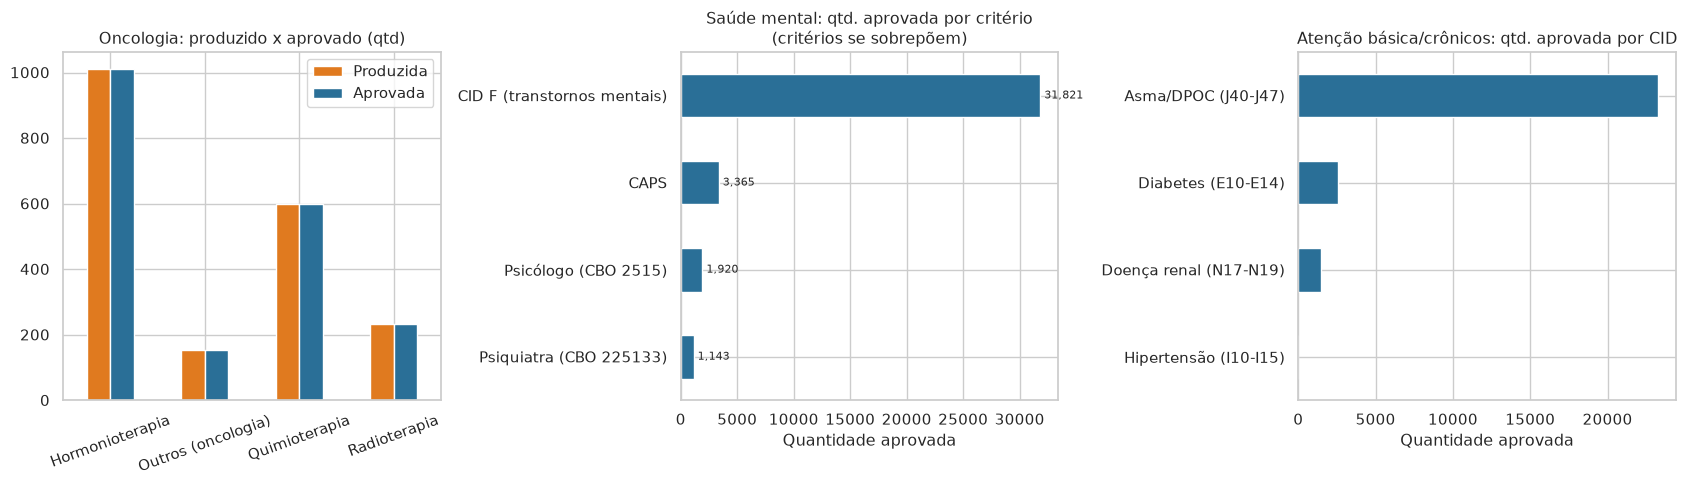

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ot = onco_t[["QtdProduzida", "QtdAprovada"]]
ot.plot(kind="bar", ax=axes[0], color=[LARANJA, AZUL], rot=20)
axes[0].set_title("Oncologia: produzido x aprovado (qtd)"); axes[0].set_xlabel(""); axes[0].legend(["Produzida", "Aprovada"])
s = saude_mental["QtdAprovada"].sort_values()
s.plot(kind="barh", ax=axes[1], color=AZUL)
for i, v in enumerate(s): axes[1].text(v, i, f" {v:,.0f}", va="center", fontsize=8)
axes[1].set_title("Saúde mental: qtd. aprovada por critério\n(critérios se sobrepõem)"); axes[1].set_xlabel("Quantidade aprovada")
c = cron.groupby("CategoriaCID")["pa_qtdapr"].sum().sort_values()
c.plot(kind="barh", ax=axes[2], color=AZUL)
axes[2].set_title("Atenção básica/crônicos: qtd. aprovada por CID"); axes[2].set_ylabel(""); axes[2].set_xlabel("Quantidade aprovada")
salvar("09_areas_criticas")

**Interpretação:**
- **Oncologia:** realizada integralmente pelo **Hospital de Clínicas** (~2.000 procedimentos, R$ 1,97 mi aprovados). Quimioterapia (600) e radioterapia (233 aprovadas contra 234 produzidas) têm aprovação praticamente total (R$ 0,91 mi e R$ 0,82 mi); a hormonioterapia (1.011) é o maior volume. Não há glosa relevante.
- **Saúde mental:** os **CAPS** (Bosque, Colmeia e Infantil) somam 3.365 atendimentos aprovados em procedimentos de CAPS (valor zero, pois são custeados por incentivo), mais 1.920 de psicólogos e 1.143 de psiquiatras (critérios se sobrepõem). Os CIDs F aparecem sobretudo em **autismo/transtornos do desenvolvimento, deficiência intelectual e esquizofrenia**; a maior parte da quantidade F (31,8 mil) é dispensação de medicamentos (clozapina, quetiapina) pela CRS.
- **Atenção básica/crônicos:** o SIASUS de Ijuí **não traz UBS** (tipo de unidade 02 ausente) e há **apenas 1 registro de hipertensão**; o acompanhamento de HAS e diabetes na APS fica no e-SUS APS e não pode ser avaliado aqui. O que existe são consultas especializadas (CISA e HCI) e 2.705 consultas médicas em atenção primária, além de medicamentos para asma/DPOC (23 mil) e diabetes (2,6 mil) dispensados pela CRS.

## 5. Conclusões e recomendações

**Principais achados**
1. A produção ambulatorial de Ijuí em 07/2026 é de ~340 mil procedimentos e R$ 5,7 mi aprovados (98,5% do apresentado), mas **59% da quantidade são medicamentos** da CRS; por isso as análises devem ser lidas com e sem medicamentos.
2. **Ijuí é polo regional:** ~63% dos atendimentos com município válido são de moradores de outros municípios, em especial Panambi, Joia, Crissiumal e Catuípe.
3. **Hospital de Clínicas** concentra a alta complexidade (toda a oncologia) e a maior produção entre os prestadores; **Bom Pastor** tem baixa taxa de aprovação em quantidade (59%) e vale auditar.
4. A **qualidade dos dados** exige atenção: CID ausente em 68%, sexo/idade/município ignorados nos consolidados e 40% de linhas duplicadas.

**Recomendações**
- Auditar a diferença apresentado x aprovado do Bom Pastor, do CISA e das cirurgias (aprovado > apresentado).
- Usar o fluxo regional nas pactuações e no planejamento de oferta (oncologia, reabilitação auditiva, CAPS).
- Complementar a análise com **e-SUS APS** para atenção básica e doenças crônicas.
- Carregar **vários meses de PARS** para analisar tendência e sazonalidade; com um único mês não é possível.
- Padronizar o preenchimento de CID, sexo, idade e município nos registros individuais (BPA-I).

**Limitações:** um único mês de movimentação; contagem por registros e quantidades, não por pacientes distintos; a remoção de duplicatas segue o enunciado e pode subestimar a produção real (-6,7% na quantidade aprovada); descrições de procedimentos com caracteres corrompidos de origem (DBF).